# Job Application Tracker: Milestone 1, the data layer
Shivani Shahi · INFO 5001 · Fall 2026

My app answers one question at a glance: **"Where does each application stand right now?"**

The data lives in two files in the `data` folder. `tracker.py` reads them into two dictionaries, and this notebook uses those to answer three real questions and check the answers. Restart and Run All runs it from top to bottom.

## The plan, in plain language
```
read steps.csv, one row per step (application, date, status)
group the rows by application, oldest step first
read details.csv, one row per application (location, skills)
answer three questions
check the answers against ones I worked out by hand
add a step without erasing the old ones, save, and load it back
```

In [1]:
import os
import matplotlib.pyplot as plt
import tracker

TODAY = "2026-11-15"   # a fixed date, so the answers below are the same every run

applications = tracker.build_applications()
details = tracker.build_details()
print(len(applications), "applications loaded")

8 applications loaded


## The library shape
Two dictionaries with the same keys. Each key is a company and a role.

- `applications` holds the steps: a list of dates and statuses, oldest first. The newest step is the last one, so it is the current status.
- `details` holds what describes the application itself (location and skills), so every step stays just a date and a status.

In [2]:
key = "BrightPath - Project Coordinator"
print(applications[key])
print(details[key])

[{'date': '2026-10-10', 'status': 'Applied'}, {'date': '2026-10-16', 'status': 'Followed up'}]
{'location': 'Sunnyvale, CA', 'skills': ['Excel', 'Jira', 'Communication']}


## Question 1: Where does each application stand right now?
The last step in each list is the newest, so `[-1]` is where it stands.

In [3]:
print(applications["BrightPath - Project Coordinator"][-1]["status"])
print()

standing = tracker.current_statuses(applications)
for name in standing:
    print(name, "->", standing[name])
print()
print(tracker.count_by_status(applications))

Followed up

BrightPath - Project Coordinator -> Followed up
Northwind Labs - Scrum Master -> Applied
Harbor Analytics - Business Analyst -> Rejected
Cedarline Health - Operations Associate -> Interview
Pixel Forge - Product Operations Intern -> Followed up
Summit Staffing - CRM Specialist -> Applied
Orbit Logistics - Project Manager -> Offer
Lumen Retail - Data Analyst -> Applied

{'Followed up': 2, 'Applied': 3, 'Rejected': 1, 'Interview': 1, 'Offer': 1}


## Question 2: Which open application should I follow up on first?
My rule: skip anything already finished (Offer, Rejected, Withdrawn). Of the rest, the one whose newest step is oldest comes first.

In [4]:
waiting = tracker.follow_up_order(applications, TODAY)
for days, name in waiting:
    print(days, "days quiet:", name)
print()
print("Follow up first:", waiting[0][1])

41 days quiet: Northwind Labs - Scrum Master
30 days quiet: BrightPath - Project Coordinator
21 days quiet: Summit Staffing - CRM Specialist
14 days quiet: Lumen Retail - Data Analyst
10 days quiet: Cedarline Health - Operations Associate
5 days quiet: Pixel Forge - Product Operations Intern

Follow up first: Northwind Labs - Scrum Master


## Question 3: Which skills do my applications ask for most?

Excel 5
Communication 5
Jira 4
Scrum 2
SQL 2


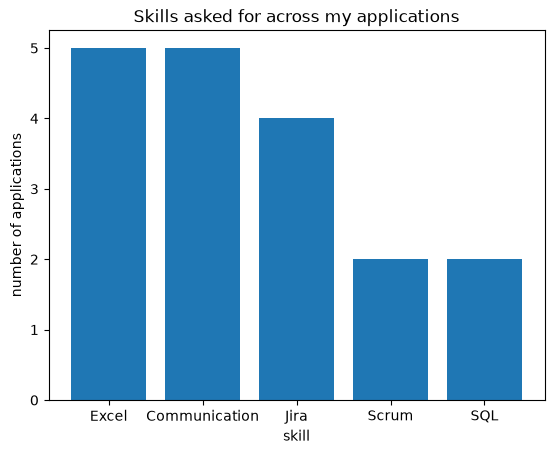

In [5]:
top = tracker.top_skills(details, 5)
for skill, count in top:
    print(skill, count)

names = []
counts = []
for skill, count in top:
    names.append(skill)
    counts.append(count)

plt.bar(names, counts)
plt.title("Skills asked for across my applications")
plt.xlabel("skill")
plt.ylabel("number of applications")
plt.show()

## Adding a step without losing the old ones, and saving
`add_step` uses `append`, which adds to the end of the list and leaves the rest alone. `save_steps` writes every step to a file, then I load that file back to see that nothing was lost. This is a copy in the `output` folder, so my real data stays as it is.

In [6]:
demo = tracker.build_applications()
name = "Northwind Labs - Scrum Master"
before = len(demo[name])

tracker.add_step(demo, name, "2026-11-14", "Followed up")
print(before, "steps ->", len(demo[name]), "steps")
print(demo[name])

saved_path = os.path.join(tracker.BASE, "output", "steps_saved.csv")
tracker.save_steps(demo, saved_path)
reloaded = tracker.build_applications(saved_path)
print()
print("after saving and loading back:")
print(reloaded[name])

1 steps -> 2 steps
[{'date': '2026-10-05', 'status': 'Applied'}, {'date': '2026-11-14', 'status': 'Followed up'}]

after saving and loading back:
[{'date': '2026-10-05', 'status': 'Applied'}, {'date': '2026-11-14', 'status': 'Followed up'}]


## SELF-CHECKs
Each one is an answer I worked out by hand from the files.

In [7]:
# SELF-CHECK 1: the tracker is not empty
assert len(applications) > 0, "no applications loaded"

# SELF-CHECK 2: BrightPath's steps are Applied (Oct 10) then Followed up (Oct 16)
assert applications["BrightPath - Project Coordinator"][-1]["status"] == "Followed up", "BrightPath should be Followed up"

# SELF-CHECK 3: Northwind applied Oct 5, and Oct 5 to Nov 15 is 41 days, the longest quiet one
assert waiting[0] == (41, "Northwind Labs - Scrum Master"), "Northwind should be first at 41 days"

# SELF-CHECK 4: counting by hand, Excel is asked for by 5 of the 8 applications
assert tracker.skill_counts(details)["Excel"] == 5, "Excel should appear 5 times"

# SELF-CHECK 5: three applications sit at Applied right now (Northwind, Summit, Lumen)
assert tracker.count_by_status(applications)["Applied"] == 3, "3 applications should be at Applied"

# SELF-CHECK 6: adding a step kept the old ones, and the new one is last
assert len(demo[name]) == before + 1, "one step should have been added"
assert demo[name][0]["status"] == "Applied", "the first step should still be there"
assert demo[name][-1]["status"] == "Followed up", "the new step should be last"

# SELF-CHECK 7: saving and loading back gives the same data, and both dictionaries share keys
assert reloaded == demo, "the saved copy should match"
assert set(applications.keys()) == set(details.keys()), "every application needs details"

print("All 7 SELF-CHECKs passed")

All 7 SELF-CHECKs passed


## What comes next
Milestone 2 moves the steps into SQLite, where each step becomes a row and stays there after the app closes, and puts the pages on top with Flask.